Similar to the exploration done in ImageNet100 and COCO2014 notebooks- here we will assess the performance of a classification model on each token separately and check if adding Register 2 to the CLS Classification Model enhances the performance of the model.

In [35]:
import sys
import os

# Adjust Python path to include the current directory (which contains 'dinov2')
sys.path.append(os.path.abspath('.'))

# Import necessary libraries
import numpy as np
import torch
import torchvision.transforms as T
from tqdm.notebook import tqdm
from PIL import Image
import pandas as pd
from pycocotools.coco import COCO
import json
import matplotlib.pyplot as plt

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)


Using device: cuda


# Load the Data

In [36]:
# Create directories for the data
os.makedirs('data/COCO2017', exist_ok=True)

# Download validation images
!wget http://images.cocodataset.org/zips/val2017.zip -P data/COCO2017/
!unzip -q data/COCO2017/val2017.zip -d data/COCO2017/
!rm data/COCO2017/val2017.zip

# Download annotations
!wget http://images.cocodataset.org/annotations/annotations_trainval2017.zip -P data/COCO2017/
!unzip -q data/COCO2017/annotations_trainval2017.zip -d data/COCO2017/
!rm data/COCO2017/annotations_trainval2017.zip


--2024-10-09 10:42:11--  http://images.cocodataset.org/zips/val2017.zip
Resolving images.cocodataset.org (images.cocodataset.org)... 52.217.165.81, 54.231.228.145, 52.217.207.81, ...
Connecting to images.cocodataset.org (images.cocodataset.org)|52.217.165.81|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 815585330 (778M) [application/zip]
Saving to: ‘data/COCO2017/val2017.zip’

val2017.zip         100%[===================>] 777.80M  57.6MB/s    in 14s     

2024-10-09 10:42:24 (56.8 MB/s) - ‘data/COCO2017/val2017.zip’ saved [815585330/815585330]

--2024-10-09 10:42:30--  http://images.cocodataset.org/annotations/annotations_trainval2017.zip
Resolving images.cocodataset.org (images.cocodataset.org)... 3.5.9.225, 52.217.64.188, 3.5.13.171, ...
Connecting to images.cocodataset.org (images.cocodataset.org)|3.5.9.225|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 252907541 (241M) [application/zip]
Saving to: ‘data/COCO2017/annotations_trai

In [70]:
# Paths to COCO data
data_dir = 'data/COCO2017/'
ann_file = os.path.join(data_dir, 'annotations/instances_val2017.json')
img_dir = os.path.join(data_dir, 'val2017')

# Initialize COCO API
coco = COCO(ann_file)

# Get all image IDs
img_ids = coco.getImgIds()

# Get category IDs and their names and supercategories
cat_ids = coco.getCatIds()
cats = coco.loadCats(cat_ids)
categories = {cat['id']: {'name': cat['name'], 'supercategory': cat['supercategory']} for cat in cats}

# Prepare the data
images = []
for img_id in tqdm(img_ids):
    img_info = coco.loadImgs(img_id)[0]
    img_filename = os.path.join(img_dir, img_info['file_name'])
    ann_ids = coco.getAnnIds(imgIds=img_id)
    anns = coco.loadAnns(ann_ids)
    # Get categories for this image
    categories_in_image = [ann['category_id'] for ann in anns]
    # Map category IDs to supercategories
    supercategory_names = [categories[cat_id]['supercategory'] for cat_id in categories_in_image]
    # For simplicity, assign the most frequent supercategory as the label
    if len(supercategory_names) > 0:
        label = max(set(supercategory_names), key=supercategory_names.count)
    else:
        label = 'background'
    images.append({
        'path': img_filename,
        'label': label,
    })

df = pd.DataFrame(images)

# Count the occurrences of each label
label_counts = df['label'].value_counts()

# Identify labels that have at least two samples
valid_labels = label_counts[label_counts >= 2].index.tolist()

# Filter the DataFrame to only include images with valid labels
df = df[df['label'].isin(valid_labels)].reset_index(drop=True)

print(f"Number of valid labels: {len(valid_labels)}")

# Split data into training and validation sets
from sklearn.model_selection import train_test_split
df_train, df_val = train_test_split(df, test_size=0.2, random_state=42, stratify=df['label'])


loading annotations into memory...
Done (t=0.70s)
creating index...
index created!


  0%|          | 0/5000 [00:00<?, ?it/s]

Number of valid labels: 13


In [73]:
print(valid_labels)

['person', 'animal', 'furniture', 'vehicle', 'sports', 'kitchen', 'food', 'indoor', 'outdoor', 'electronic', 'accessory', 'appliance', 'background']


# Compute Embeddings

In [74]:
import torch
import torchvision.transforms as T

# Path to the pre-trained model in Colab (adjust this to your given path)
checkpoint_path = '/content/DINOv2RegisterExploration/dinov2_vits14_reg4_pretrain.pth'

# Use torch.hub.load to load the model from the local repository
dinov2_vits14 = torch.hub.load('/content/DINOv2RegisterExploration', 'dinov2_vits14_reg', source='local')

# Set device to GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else "cpu")
dinov2_vits14.to(device)

# Define the image transformation
transform_image = T.Compose([
    T.ToTensor(),
    T.Resize(244),
    T.CenterCrop(224),
    T.Normalize([0.5], [0.5])
])

print("Model loaded and ready!")


Model loaded and ready!


In [75]:
def load_image(img_path: str) -> torch.Tensor:
    """
    Load an image and return a tensor that can be used as an input to DINOv2.
    """
    img = Image.open(img_path).convert('RGB')
    transformed_img = transform_image(img).unsqueeze(0)
    return transformed_img

def compute_embeddings(files: list) -> dict:
    all_embeddings = {}
    excluded_files = []

    with torch.no_grad():
        for i, file in enumerate(tqdm(files)):
            try:
                embeddings = dinov2_vits14(load_image(file).to(device), return_register_tokens=True)
                patch_tokens, class_tokens, register_tokens = embeddings[0]
                all_embeddings[file] = {
                    "patch_tokens": patch_tokens.cpu().numpy(),
                    "class_tokens": class_tokens.cpu().numpy(),
                    "register_tokens": register_tokens.cpu().numpy()
                }
            except Exception as e:
                print(f"Error processing {file}: {e}")
                excluded_files.append(file)

    return all_embeddings, excluded_files


In [76]:
# Compute embeddings for the training set
train_embeddings, excluded_train_files = compute_embeddings(list(df_train['path']))

# Compute embeddings for the validation set
val_embeddings, excluded_val_files = compute_embeddings(list(df_val['path']))


  0%|          | 0/4000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

In [77]:
def save_embeddings(embeddings, save_dir):
    """
    Save embeddings and metadata to the specified directory.
    """
    if not os.path.exists(save_dir):
        os.makedirs(save_dir)

    metadata = {}
    for filename, embedding in embeddings.items():
        base_name = os.path.splitext(os.path.basename(filename))[0]
        npy_file = f"{base_name}.npy"
        np.save(os.path.join(save_dir, npy_file), embedding)
        metadata[filename] = npy_file

    with open(os.path.join(save_dir, "metadata.json"), "w") as f:
        json.dump(metadata, f)

# Save the training embeddings
train_dir = os.path.join(os.getcwd(), "train_embeddings")
save_embeddings(train_embeddings, train_dir)

# Save the validation embeddings
val_dir = os.path.join(os.getcwd(), "val_embeddings")
save_embeddings(val_embeddings, val_dir)


In [78]:
def load_embeddings(load_dir: str, embedding_type: str) -> dict:
    """
    Load specified type of embeddings and convert them to the desired nested dictionary format.
    """
    if embedding_type not in ['class_tokens', 'patch_tokens', 'register_tokens']:
        raise ValueError("Invalid embedding type. Must be 'class_tokens', 'patch_tokens', or 'register_tokens'.")

    with open(os.path.join(load_dir, "metadata.json"), "r") as f:
        metadata = json.load(f)

    embeddings = {}
    for filename, npy_file in tqdm(metadata.items(), desc=f"Loading {embedding_type}"):
        # Load the numpy array
        loaded_embedding = np.load(os.path.join(load_dir, npy_file), allow_pickle=True).item()
        # Extract the specified type of embedding
        embeddings[filename] = loaded_embedding[embedding_type]

    return embeddings

# Load the training embeddings
train_embeddings_cls = load_embeddings(train_dir, "class_tokens")
train_embeddings_reg = load_embeddings(train_dir, "register_tokens")

# Load the validation embeddings
val_embeddings_cls = load_embeddings(val_dir, "class_tokens")
val_embeddings_reg = load_embeddings(val_dir, "register_tokens")


Loading class_tokens:   0%|          | 0/4000 [00:00<?, ?it/s]

Loading register_tokens:   0%|          | 0/4000 [00:00<?, ?it/s]

Loading class_tokens:   0%|          | 0/1000 [00:00<?, ?it/s]

Loading register_tokens:   0%|          | 0/1000 [00:00<?, ?it/s]

In [79]:
# Create label mappings
labels_mapping = {label: idx for idx, label in enumerate(sorted(valid_labels))}

# Save labels mapping for future use
with open("labels_mapping.json", "w") as f:
    json.dump(labels_mapping, f)


In [80]:
def extract_features_labels(embeddings, labels_df, labels_mapping, embedding_type, reg=0):
    X = []
    y = []
    for filename, embedding in embeddings.items():
        # Update label extraction to ensure consistency
        label_name = labels_df.loc[labels_df['path'] == filename, 'label'].values[0]
        label_idx = labels_mapping[label_name]

        if embedding_type == 'class_tokens':
            feature = np.array(embedding[0])
        elif embedding_type == 'register_tokens':
            if reg == 'all':
                registers = np.concatenate(embedding[0], axis=0)
                feature = registers
            else:
                feature = np.array(embedding[0][reg])
        else:
            raise ValueError("Invalid embedding type. Must be 'class_tokens' or 'register_tokens'.")

        X.append(feature)
        y.append(label_idx)
    return np.array(X), np.array(y)

# Extract features and labels for class tokens
X_train_cls, y_train_cls = extract_features_labels(train_embeddings_cls, df_train, labels_mapping, 'class_tokens')
X_val_cls, y_val_cls = extract_features_labels(val_embeddings_cls, df_val, labels_mapping, 'class_tokens')

# Extract features and labels for register tokens (using all registers)
X_train_reg, y_train_reg = extract_features_labels(train_embeddings_reg, df_train, labels_mapping, 'register_tokens', reg='all')
X_val_reg, y_val_reg = extract_features_labels(val_embeddings_reg, df_val, labels_mapping, 'register_tokens', reg='all')


# Predicting the CLS Token using the Registers 

In [83]:
def prepare_data_for_regression(register_embeddings, cls_embeddings):
    X = []
    y = []
    for filename in register_embeddings.keys():
        reg_embedding = np.concatenate(register_embeddings[filename][0], axis=0)
        cls_embedding = cls_embeddings[filename][0]
        X.append(reg_embedding)
        y.append(cls_embedding)
    return np.array(X), np.array(y)

# Prepare data
X_train_regress, y_train_regress = prepare_data_for_regression(train_embeddings_reg, train_embeddings_cls)
X_val_regress, y_val_regress = prepare_data_for_regression(val_embeddings_reg, val_embeddings_cls)

# Convert to tensors
X_train_regress = torch.tensor(X_train_regress, dtype=torch.float32).to(device)
y_train_regress = torch.tensor(y_train_regress, dtype=torch.float32).to(device)
X_val_regress = torch.tensor(X_val_regress, dtype=torch.float32).to(device)
y_val_regress = torch.tensor(y_val_regress, dtype=torch.float32).to(device)


100%|██████████| 100/100 [00:00<00:00, 467.63it/s]


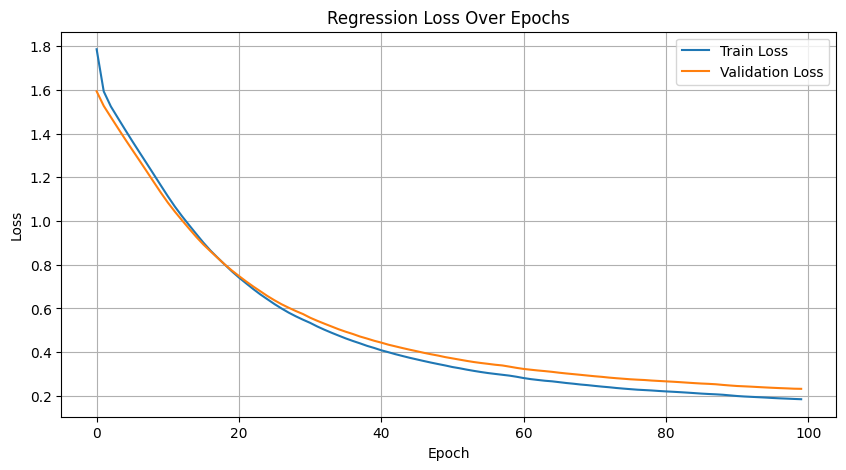

In [84]:
class RegisterToCLSModel(nn.Module):
    def __init__(self, input_size, output_size):
        super(RegisterToCLSModel, self).__init__()
        self.fc1 = nn.Linear(input_size, 512)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(512, output_size)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

def train_regression_model(X_train, y_train, X_val, y_val, epochs=100):
    model = RegisterToCLSModel(X_train.shape[1], y_train.shape[1]).to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    train_losses = []
    val_losses = []

    for epoch in trange(epochs):
        model.train()
        optimizer.zero_grad()
        outputs = model(X_train)
        loss = criterion(outputs, y_train)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_outputs = model(X_val)
            val_loss = criterion(val_outputs, y_val)

        train_losses.append(loss.item())
        val_losses.append(val_loss.item())

    return model, train_losses, val_losses

# Train the regression model
model_regress, train_losses, val_losses = train_regression_model(X_train_regress, y_train_regress, X_val_regress, y_val_regress)

# Plot losses
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Regression Loss Over Epochs')
plt.legend()
plt.grid(True)
plt.show()


# Classification Model on Register Tokens 

In [93]:
# Load necessary libraries
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from tqdm import trange
import matplotlib.pyplot as plt

# Assuming the embeddings have been saved and the labels_mapping has been created
train_embeddings_cls = load_embeddings(train_dir, "class_tokens")
val_embeddings_cls = load_embeddings(val_dir, "class_tokens")
train_embeddings_reg = load_embeddings(train_dir, "register_tokens")
val_embeddings_reg = load_embeddings(val_dir, "register_tokens")

# Load the labels mapping
with open("labels_mapping.json", "r") as f:
    labels_mapping = json.load(f)


Loading class_tokens:   0%|          | 0/4000 [00:00<?, ?it/s]

Loading class_tokens:   0%|          | 0/1000 [00:00<?, ?it/s]

Loading register_tokens:   0%|          | 0/4000 [00:00<?, ?it/s]

Loading register_tokens:   0%|          | 0/1000 [00:00<?, ?it/s]

In [94]:
def extract_features_labels(embeddings, labels_df, labels_mapping, embedding_type, reg=0):
    X = []
    y = []
    for filename, embedding in embeddings.items():
        label_name = labels_df.loc[labels_df['path'] == filename, 'label'].values[0]
        label_idx = labels_mapping[label_name]

        if embedding_type == 'class_tokens':
            feature = np.array(embedding[0])  # Extract the class token embedding
        elif embedding_type == 'register_tokens':
            feature = np.array(embedding[0][reg])  # Extract the specified register token
        else:
            raise ValueError("Invalid embedding type. Must be 'class_tokens' or 'register_tokens'.")

        X.append(feature)
        y.append(label_idx)
    return np.array(X), np.array(y)



Training classifier using Register Token 0



Training Epochs:  20%|██        | 2/10 [00:00<00:01,  7.62it/s]

Epoch 1/10 - Train Loss: 1.7019 - Train Acc: 0.4415 - Val Loss: 1.1733 - Val Acc: 0.5980
Epoch 2/10 - Train Loss: 1.0491 - Train Acc: 0.6462 - Val Loss: 1.0152 - Val Acc: 0.6570


Training Epochs:  40%|████      | 4/10 [00:00<00:00,  7.39it/s]

Epoch 3/10 - Train Loss: 0.9095 - Train Acc: 0.6965 - Val Loss: 0.9708 - Val Acc: 0.6630
Epoch 4/10 - Train Loss: 0.8326 - Train Acc: 0.7165 - Val Loss: 0.9454 - Val Acc: 0.6610


Training Epochs:  60%|██████    | 6/10 [00:00<00:00,  7.53it/s]

Epoch 5/10 - Train Loss: 0.7823 - Train Acc: 0.7332 - Val Loss: 0.9351 - Val Acc: 0.6720
Epoch 6/10 - Train Loss: 0.7428 - Train Acc: 0.7512 - Val Loss: 0.9381 - Val Acc: 0.6660


Training Epochs:  80%|████████  | 8/10 [00:01<00:00,  7.45it/s]

Epoch 7/10 - Train Loss: 0.7109 - Train Acc: 0.7650 - Val Loss: 0.9324 - Val Acc: 0.6700
Epoch 8/10 - Train Loss: 0.6852 - Train Acc: 0.7720 - Val Loss: 0.9343 - Val Acc: 0.6670


Training Epochs: 100%|██████████| 10/10 [00:01<00:00,  7.48it/s]

Epoch 9/10 - Train Loss: 0.6605 - Train Acc: 0.7812 - Val Loss: 0.9388 - Val Acc: 0.6690
Epoch 10/10 - Train Loss: 0.6437 - Train Acc: 0.7802 - Val Loss: 0.9421 - Val Acc: 0.6690


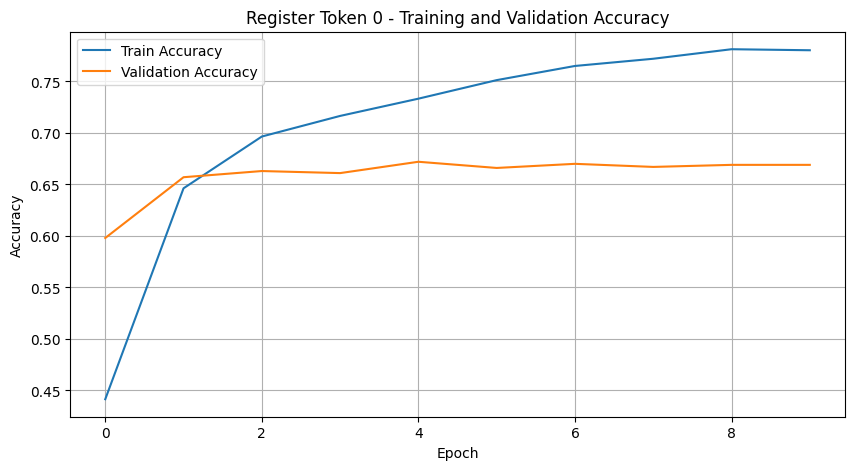


Training classifier using Register Token 1



Training Epochs:  20%|██        | 2/10 [00:00<00:01,  7.24it/s]

Epoch 1/10 - Train Loss: 2.0972 - Train Acc: 0.3083 - Val Loss: 1.7504 - Val Acc: 0.5070
Epoch 2/10 - Train Loss: 1.5660 - Train Acc: 0.5065 - Val Loss: 1.4100 - Val Acc: 0.5740


Training Epochs:  40%|████      | 4/10 [00:00<00:00,  7.41it/s]

Epoch 3/10 - Train Loss: 1.3341 - Train Acc: 0.5810 - Val Loss: 1.2647 - Val Acc: 0.5880
Epoch 4/10 - Train Loss: 1.2070 - Train Acc: 0.6070 - Val Loss: 1.1660 - Val Acc: 0.6270


Training Epochs:  60%|██████    | 6/10 [00:00<00:00,  7.23it/s]

Epoch 5/10 - Train Loss: 1.1263 - Train Acc: 0.6382 - Val Loss: 1.1098 - Val Acc: 0.6370
Epoch 6/10 - Train Loss: 1.0679 - Train Acc: 0.6500 - Val Loss: 1.0722 - Val Acc: 0.6390


Training Epochs:  80%|████████  | 8/10 [00:01<00:00,  7.16it/s]

Epoch 7/10 - Train Loss: 1.0349 - Train Acc: 0.6532 - Val Loss: 1.0403 - Val Acc: 0.6560
Epoch 8/10 - Train Loss: 1.0007 - Train Acc: 0.6650 - Val Loss: 1.0117 - Val Acc: 0.6610


Training Epochs: 100%|██████████| 10/10 [00:01<00:00,  7.19it/s]

Epoch 9/10 - Train Loss: 0.9720 - Train Acc: 0.6760 - Val Loss: 1.0082 - Val Acc: 0.6520
Epoch 10/10 - Train Loss: 0.9571 - Train Acc: 0.6727 - Val Loss: 0.9820 - Val Acc: 0.6780


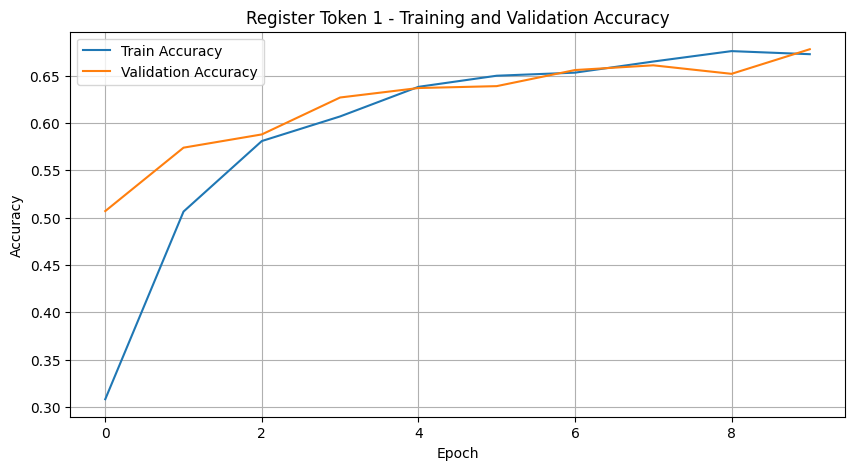


Training classifier using Register Token 2



Training Epochs:  20%|██        | 2/10 [00:00<00:01,  7.44it/s]

Epoch 1/10 - Train Loss: 1.6411 - Train Acc: 0.4535 - Val Loss: 1.1870 - Val Acc: 0.6050
Epoch 2/10 - Train Loss: 1.0554 - Train Acc: 0.6362 - Val Loss: 1.0442 - Val Acc: 0.6500


Training Epochs:  40%|████      | 4/10 [00:00<00:00,  7.42it/s]

Epoch 3/10 - Train Loss: 0.9255 - Train Acc: 0.6780 - Val Loss: 0.9930 - Val Acc: 0.6490
Epoch 4/10 - Train Loss: 0.8533 - Train Acc: 0.7043 - Val Loss: 0.9805 - Val Acc: 0.6640


Training Epochs:  60%|██████    | 6/10 [00:00<00:00,  7.40it/s]

Epoch 5/10 - Train Loss: 0.8058 - Train Acc: 0.7220 - Val Loss: 0.9678 - Val Acc: 0.6560
Epoch 6/10 - Train Loss: 0.7645 - Train Acc: 0.7345 - Val Loss: 0.9570 - Val Acc: 0.6670


Training Epochs:  80%|████████  | 8/10 [00:01<00:00,  7.40it/s]

Epoch 7/10 - Train Loss: 0.7341 - Train Acc: 0.7450 - Val Loss: 0.9524 - Val Acc: 0.6770
Epoch 8/10 - Train Loss: 0.7080 - Train Acc: 0.7558 - Val Loss: 0.9632 - Val Acc: 0.6680


Training Epochs: 100%|██████████| 10/10 [00:01<00:00,  7.37it/s]

Epoch 9/10 - Train Loss: 0.6879 - Train Acc: 0.7612 - Val Loss: 0.9559 - Val Acc: 0.6730
Epoch 10/10 - Train Loss: 0.6672 - Train Acc: 0.7658 - Val Loss: 0.9612 - Val Acc: 0.6690


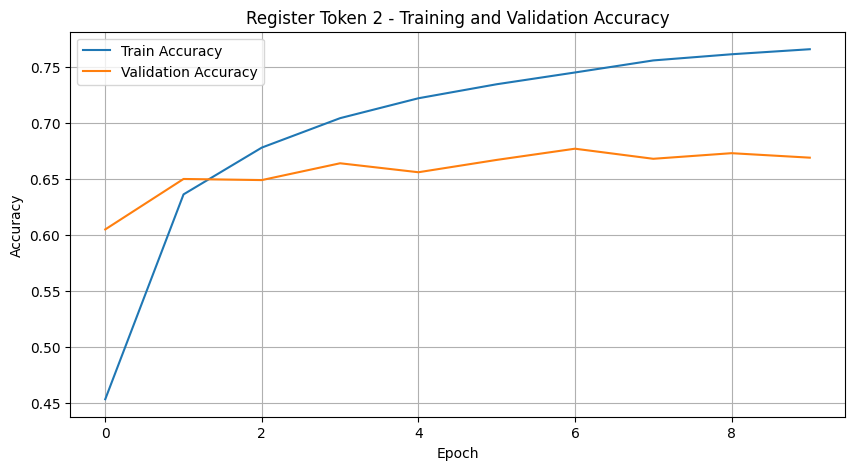


Training classifier using Register Token 3



Training Epochs:  20%|██        | 2/10 [00:00<00:01,  7.46it/s]

Epoch 1/10 - Train Loss: 1.6170 - Train Acc: 0.4645 - Val Loss: 1.1389 - Val Acc: 0.6220
Epoch 2/10 - Train Loss: 1.0337 - Train Acc: 0.6452 - Val Loss: 1.0070 - Val Acc: 0.6500


Training Epochs:  40%|████      | 4/10 [00:00<00:00,  7.43it/s]

Epoch 3/10 - Train Loss: 0.9062 - Train Acc: 0.6923 - Val Loss: 0.9568 - Val Acc: 0.6650
Epoch 4/10 - Train Loss: 0.8346 - Train Acc: 0.7125 - Val Loss: 0.9376 - Val Acc: 0.6700


Training Epochs:  60%|██████    | 6/10 [00:00<00:00,  7.45it/s]

Epoch 5/10 - Train Loss: 0.7856 - Train Acc: 0.7265 - Val Loss: 0.9330 - Val Acc: 0.6800
Epoch 6/10 - Train Loss: 0.7484 - Train Acc: 0.7375 - Val Loss: 0.9324 - Val Acc: 0.6640


Training Epochs:  80%|████████  | 8/10 [00:01<00:00,  7.52it/s]

Epoch 7/10 - Train Loss: 0.7192 - Train Acc: 0.7528 - Val Loss: 0.9217 - Val Acc: 0.6630
Epoch 8/10 - Train Loss: 0.6931 - Train Acc: 0.7592 - Val Loss: 0.9240 - Val Acc: 0.6660


Training Epochs: 100%|██████████| 10/10 [00:01<00:00,  7.04it/s]

Epoch 9/10 - Train Loss: 0.6714 - Train Acc: 0.7690 - Val Loss: 0.9283 - Val Acc: 0.6740
Epoch 10/10 - Train Loss: 0.6518 - Train Acc: 0.7708 - Val Loss: 0.9338 - Val Acc: 0.6630


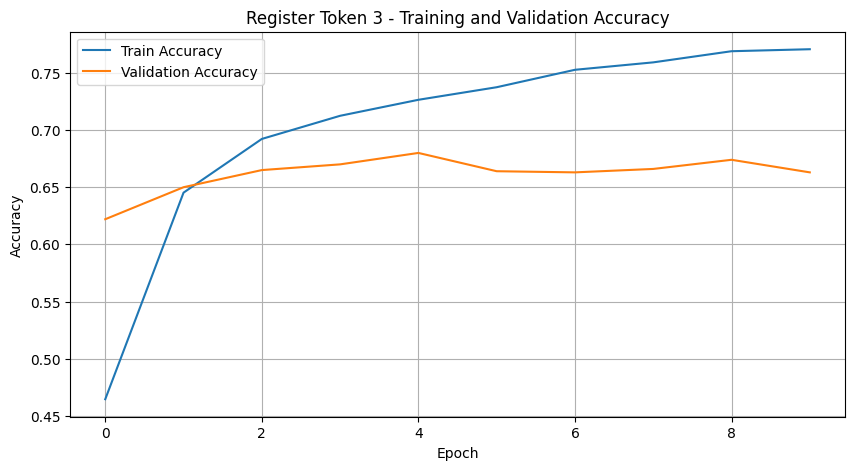

In [95]:
# Number of classes
num_classes = len(labels_mapping)

# Initialize lists to store results
register_train_accuracies = []
register_val_accuracies = []
register_models = []

# Loop over each register token
for reg_idx in range(4):
    print(f"\nTraining classifier using Register Token {reg_idx}\n")

    # Extract features and labels for the current register token
    X_train_reg, y_train_reg = extract_features_labels(train_embeddings_reg, df_train, labels_mapping, 'register_tokens', reg=reg_idx)
    X_val_reg, y_val_reg = extract_features_labels(val_embeddings_reg, df_val, labels_mapping, 'register_tokens', reg=reg_idx)

    # Convert data to PyTorch tensors
    X_train_tensor = torch.tensor(X_train_reg, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train_reg, dtype=torch.long)
    X_val_tensor = torch.tensor(X_val_reg, dtype=torch.float32)
    y_val_tensor = torch.tensor(y_val_reg, dtype=torch.long)

    # Create datasets and data loaders
    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

    # Initialize the model
    input_size = X_train_reg.shape[1]
    model = Classifier(input_size, num_classes).to(device)

    # Define loss function and optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Train the classifier
    train_losses, val_losses, train_accuracies, val_accuracies = train_classifier(
        model, criterion, optimizer, train_loader, val_loader, epochs=10
    )

    # Store results
    register_train_accuracies.append(train_accuracies)
    register_val_accuracies.append(val_accuracies)
    register_models.append(model)

    # Plot training and validation accuracy for this register token
    plt.figure(figsize=(10, 5))
    plt.plot(train_accuracies, label='Train Accuracy')
    plt.plot(val_accuracies, label='Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.title(f'Register Token {reg_idx} - Training and Validation Accuracy')
    plt.legend()
    plt.grid(True)
    plt.show()


# Classification Model on CLS Token 


Training classifier using CLS Token



Training Epochs:  20%|██        | 2/10 [00:00<00:01,  7.46it/s]

Epoch 1/10 - Train Loss: 1.7503 - Train Acc: 0.4343 - Val Loss: 1.2565 - Val Acc: 0.5730
Epoch 2/10 - Train Loss: 1.1026 - Train Acc: 0.6275 - Val Loss: 1.0876 - Val Acc: 0.6150


Training Epochs:  40%|████      | 4/10 [00:00<00:00,  7.50it/s]

Epoch 3/10 - Train Loss: 0.9495 - Train Acc: 0.6795 - Val Loss: 1.0241 - Val Acc: 0.6420
Epoch 4/10 - Train Loss: 0.8658 - Train Acc: 0.7075 - Val Loss: 1.0017 - Val Acc: 0.6440


Training Epochs:  60%|██████    | 6/10 [00:00<00:00,  7.51it/s]

Epoch 5/10 - Train Loss: 0.8072 - Train Acc: 0.7238 - Val Loss: 0.9872 - Val Acc: 0.6500
Epoch 6/10 - Train Loss: 0.7669 - Train Acc: 0.7398 - Val Loss: 0.9828 - Val Acc: 0.6570


Training Epochs:  80%|████████  | 8/10 [00:01<00:00,  7.53it/s]

Epoch 7/10 - Train Loss: 0.7314 - Train Acc: 0.7492 - Val Loss: 0.9765 - Val Acc: 0.6580
Epoch 8/10 - Train Loss: 0.7025 - Train Acc: 0.7625 - Val Loss: 0.9817 - Val Acc: 0.6580


Training Epochs: 100%|██████████| 10/10 [00:01<00:00,  7.46it/s]

Epoch 9/10 - Train Loss: 0.6796 - Train Acc: 0.7705 - Val Loss: 0.9860 - Val Acc: 0.6600
Epoch 10/10 - Train Loss: 0.6575 - Train Acc: 0.7748 - Val Loss: 0.9865 - Val Acc: 0.6640


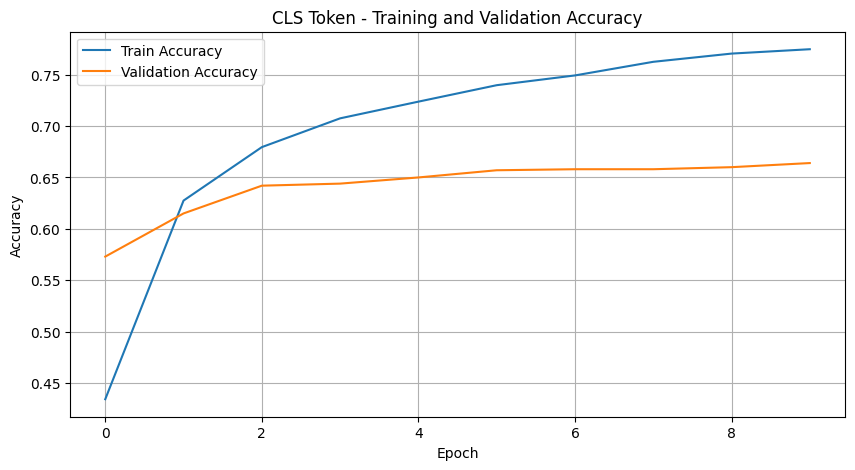

In [99]:
print("\nTraining classifier using CLS Token\n")

# Extract features and labels for the CLS token
X_train_cls, y_train_cls = extract_features_labels(train_embeddings_cls, df_train, labels_mapping, 'class_tokens')
X_val_cls, y_val_cls = extract_features_labels(val_embeddings_cls, df_val, labels_mapping, 'class_tokens')

# Convert data to PyTorch tensors
X_train_tensor = torch.tensor(X_train_cls, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_cls, dtype=torch.long)
X_val_tensor = torch.tensor(X_val_cls, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_cls, dtype=torch.long)

# Create datasets and data loaders
train_dataset_cls = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset_cls = TensorDataset(X_val_tensor, y_val_tensor)

train_loader_cls = DataLoader(train_dataset_cls, batch_size=64, shuffle=True)
val_loader_cls = DataLoader(val_dataset_cls, batch_size=64, shuffle=False)

# Initialize the model
input_size = X_train_cls.shape[1]
num_classes = len(labels_mapping)
model_cls_token = Classifier(input_size, num_classes).to(device)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_cls_token.parameters(), lr=0.001)

# Train the classifier
train_losses_cls, val_losses_cls, train_accuracies_cls, val_accuracies_cls = train_classifier(
    model_cls_token, criterion, optimizer, train_loader_cls, val_loader_cls, epochs=10
)

# Plot training and validation accuracy for the CLS token
plt.figure(figsize=(10, 5))
plt.plot(train_accuracies_cls, label='Train Accuracy')
plt.plot(val_accuracies_cls, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('CLS Token - Training and Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()


# Comparison Between Different Classification Models 

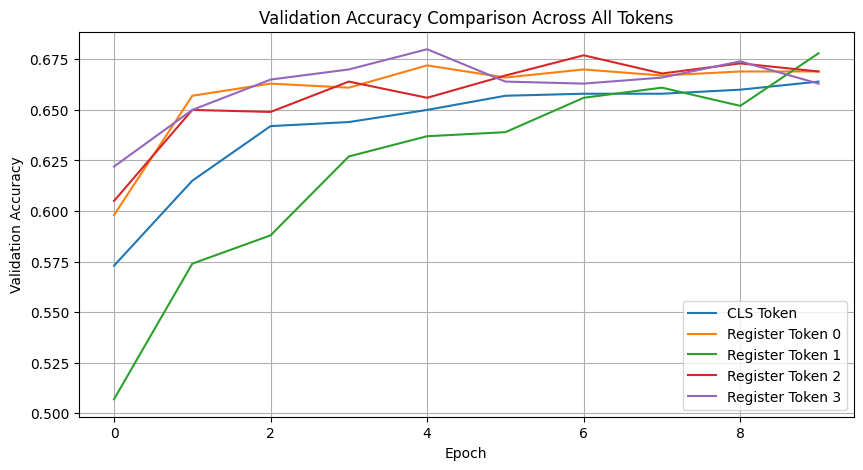

In [102]:
# Combine validation accuracies of CLS token and register tokens
plt.figure(figsize=(10, 5))

# Plot validation accuracy for CLS token
plt.plot(val_accuracies_cls, label='CLS Token')

# Plot validation accuracies for each register token
for reg_idx in range(4):
    plt.plot(register_val_accuracies[reg_idx], label=f'Register Token {reg_idx}')

plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.title('Validation Accuracy Comparison Across All Tokens')
plt.legend()
plt.grid(True)
plt.show()


# Classification Model on CLS and Register 2 (Concatenated)

Note: the code indexes registers from 0, so `reg=1` and the label "Register Token 1" below refer to Register 2 in the report and README.


Training classifier using CLS Token concatenated with Register Token 1



Training Epochs:  20%|██        | 2/10 [00:00<00:01,  6.84it/s]

Epoch 1/10 - Train Loss: 1.5155 - Train Acc: 0.5008 - Val Loss: 1.1087 - Val Acc: 0.6170
Epoch 2/10 - Train Loss: 0.9835 - Train Acc: 0.6613 - Val Loss: 0.9939 - Val Acc: 0.6550


Training Epochs:  40%|████      | 4/10 [00:00<00:00,  6.83it/s]

Epoch 3/10 - Train Loss: 0.8569 - Train Acc: 0.7035 - Val Loss: 0.9689 - Val Acc: 0.6660
Epoch 4/10 - Train Loss: 0.7875 - Train Acc: 0.7305 - Val Loss: 0.9503 - Val Acc: 0.6740


Training Epochs:  60%|██████    | 6/10 [00:00<00:00,  6.55it/s]

Epoch 5/10 - Train Loss: 0.7344 - Train Acc: 0.7535 - Val Loss: 0.9606 - Val Acc: 0.6590
Epoch 6/10 - Train Loss: 0.6971 - Train Acc: 0.7590 - Val Loss: 0.9501 - Val Acc: 0.6760


Training Epochs:  80%|████████  | 8/10 [00:01<00:00,  6.57it/s]

Epoch 7/10 - Train Loss: 0.6669 - Train Acc: 0.7718 - Val Loss: 0.9563 - Val Acc: 0.6890
Epoch 8/10 - Train Loss: 0.6384 - Train Acc: 0.7782 - Val Loss: 0.9564 - Val Acc: 0.6770


Training Epochs: 100%|██████████| 10/10 [00:01<00:00,  6.66it/s]

Epoch 9/10 - Train Loss: 0.6118 - Train Acc: 0.7915 - Val Loss: 0.9652 - Val Acc: 0.6760
Epoch 10/10 - Train Loss: 0.5990 - Train Acc: 0.7907 - Val Loss: 0.9666 - Val Acc: 0.6680


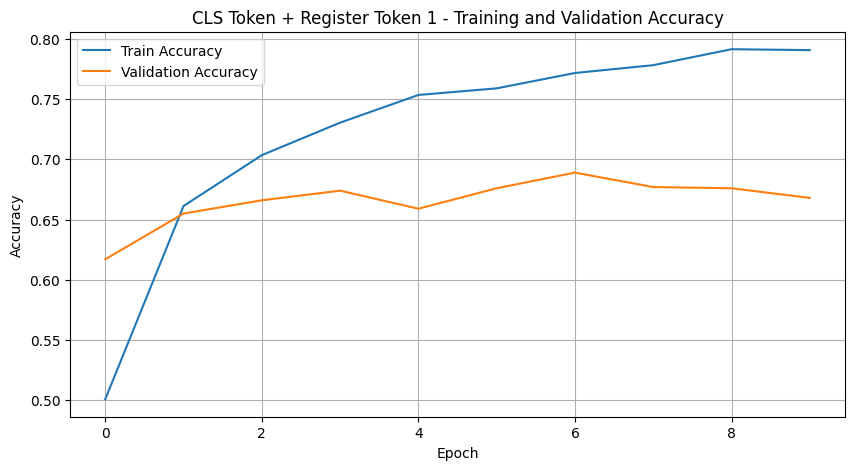

In [103]:
print("\nTraining classifier using CLS Token concatenated with Register Token 1\n")

# Step 1: Extract features for CLS token and Register Token 1
# Extract CLS token features
X_train_cls, y_train_cls = extract_features_labels(train_embeddings_cls, df_train, labels_mapping, 'class_tokens')
X_val_cls, y_val_cls = extract_features_labels(val_embeddings_cls, df_val, labels_mapping, 'class_tokens')

# Extract Register Token 1 features
X_train_reg1, y_train_reg1 = extract_features_labels(train_embeddings_reg, df_train, labels_mapping, 'register_tokens', reg=1)
X_val_reg1, y_val_reg1 = extract_features_labels(val_embeddings_reg, df_val, labels_mapping, 'register_tokens', reg=1)

# Step 2: Concatenate CLS token features with Register Token 1 features
X_train_concat = np.concatenate((X_train_cls, X_train_reg1), axis=1)
X_val_concat = np.concatenate((X_val_cls, X_val_reg1), axis=1)

# Labels remain the same
y_train_concat = y_train_cls
y_val_concat = y_val_cls

# Step 3: Convert data to PyTorch tensors
X_train_tensor = torch.tensor(X_train_concat, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_concat, dtype=torch.long)
X_val_tensor = torch.tensor(X_val_concat, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_concat, dtype=torch.long)

# Create datasets and data loaders
train_dataset_concat = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset_concat = TensorDataset(X_val_tensor, y_val_tensor)

train_loader_concat = DataLoader(train_dataset_concat, batch_size=64, shuffle=True)
val_loader_concat = DataLoader(val_dataset_concat, batch_size=64, shuffle=False)

# Step 4: Initialize the model
input_size = X_train_concat.shape[1]
num_classes = len(labels_mapping)
model_concat = Classifier(input_size, num_classes).to(device)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_concat.parameters(), lr=0.001)

# Step 5: Train the classifier
train_losses_concat, val_losses_concat, train_accuracies_concat, val_accuracies_concat = train_classifier(
    model_concat, criterion, optimizer, train_loader_concat, val_loader_concat, epochs=10
)

# Plot training and validation accuracy for the concatenated features
plt.figure(figsize=(10, 5))
plt.plot(train_accuracies_concat, label='Train Accuracy')
plt.plot(val_accuracies_concat, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('CLS Token + Register Token 1 - Training and Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
def evaluate_model(model, data_loader):
    model.eval()
    correct_preds = 0
    total_preds = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)

            total_preds += labels.size(0)
            correct_preds += (predicted == labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    accuracy = correct_preds / total_preds
    return accuracy, all_preds, all_labels

In [104]:
# Evaluate the concatenated model on the validation set
val_accuracy_concat, val_preds_concat, val_labels_concat = evaluate_model(model_concat, val_loader_concat)
print(f'CLS Token + Register Token 1 - Validation Accuracy: {val_accuracy_concat * 100:.2f}%')


CLS Token + Register Token 1 - Validation Accuracy: 66.80%
